# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor


In [2]:
df = pd.read_csv('data/temps.csv')

In [3]:
df.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    str    
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 24.6 KB


In [5]:
df.describe()

,year,month,day,temp_2,temp_1,average,actual,friend
count,348.0,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000,348.000000
mean,2016.0,6.477011,15.514368,62.652299,62.701149,59.760632,62.543103,60.034483
std,0.0,3.498380,8.772982,12.165398,12.120542,10.527306,11.794146,15.626179
min,2016.0,1.000000,1.000000,35.000000,35.000000,45.100000,35.000000,28.000000
25%,2016.0,3.000000,8.000000,54.000000,54.000000,49.975000,54.000000,47.750000
50%,2016.0,6.000000,15.000000,62.500000,62.500000,58.200000,62.500000,60.000000
75%,2016.0,10.000000,23.000000,71.000000,71.000000,69.025000,71.000000,71.000000
max,2016.0,12.000000,31.000000,117.000000,117.000000,77.400000,92.000000,95.000000


In [6]:
#Veo arriba que 'year' es un valor cto igual a 2016 por lo que me  puedo cargar esa columna.
df = df.drop(columns=['year'])

### 2. Realiza un análisis exploratorio junto con un Feature Engineering

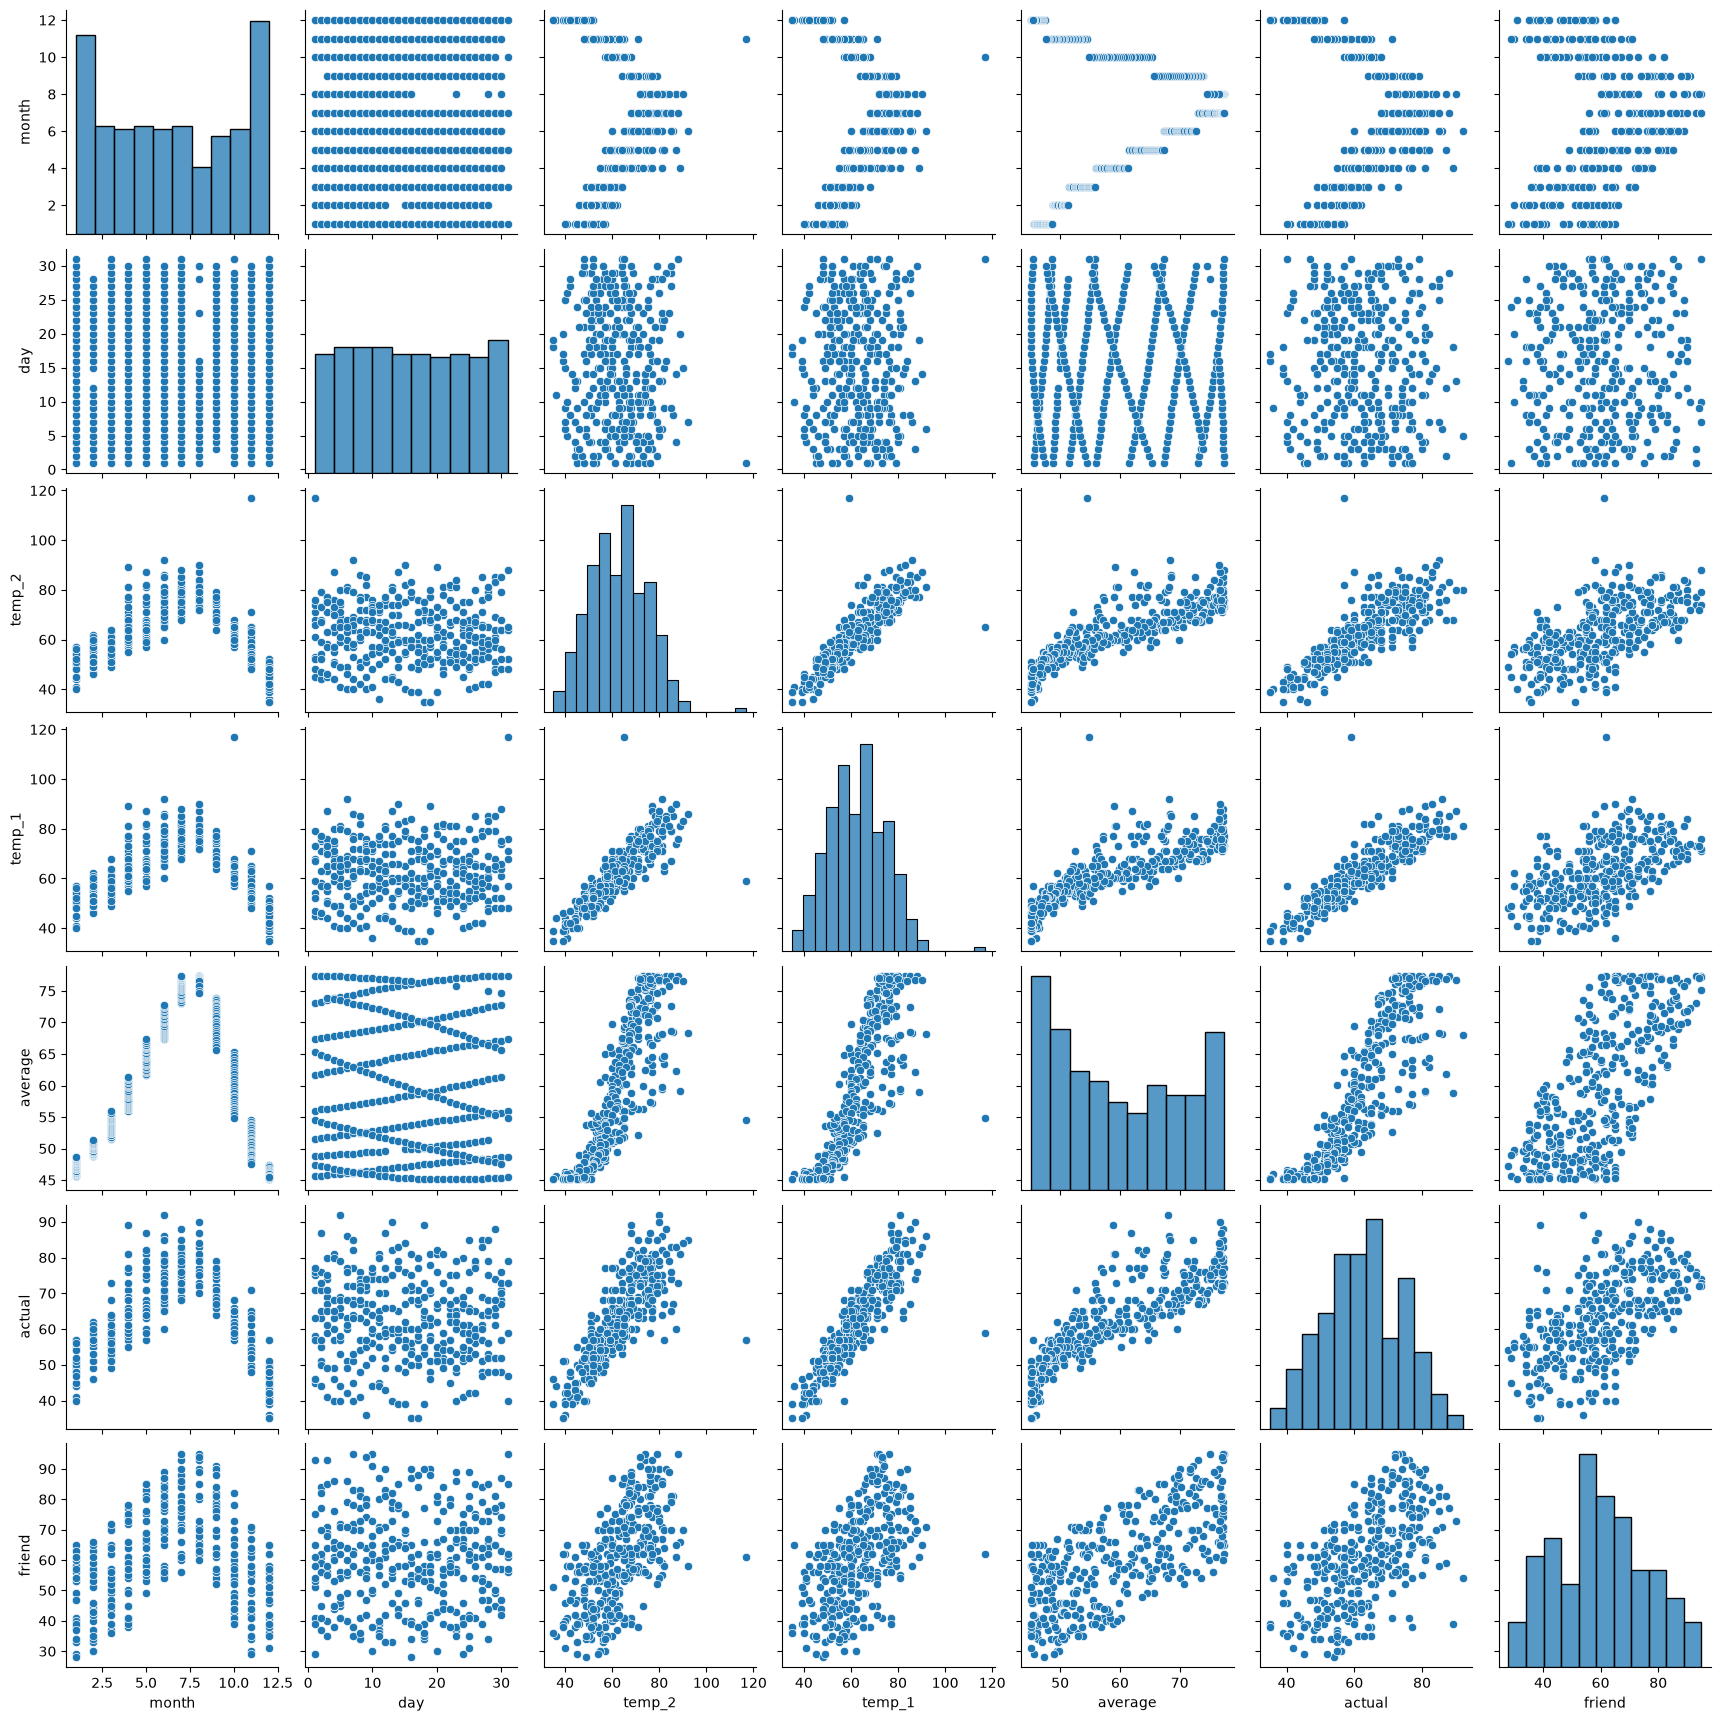

In [7]:
sns.pairplot(df);

<Axes: >

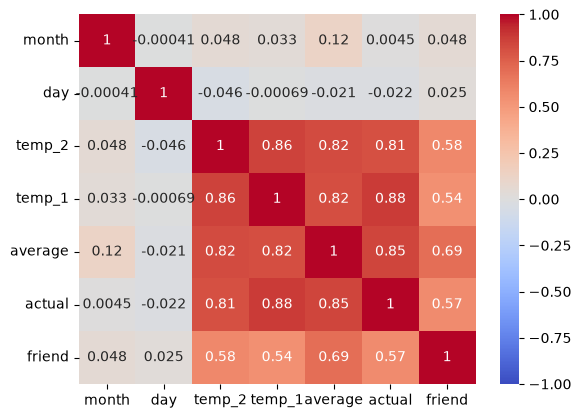

In [8]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1)

### 3. Selecciona variables y divide en train y test

In [9]:
X = df[['temp_2','temp_1','average','friend']]
y = df['actual']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

### 4. Entrena el modelo


In [11]:
from sklearn.tree import DecisionTreeRegressor

modelo = DecisionTreeRegressor(max_depth=2, random_state=42)
modelo.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [12]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R2 (Coeficiente de determinación): {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

R2 (Coeficiente de determinación): 0.7308
MAE: 4.8888
MAPE: 0.0774
MSE: 37.6479
RMSE: 6.1358


In [13]:
y_pred_train = modelo.predict(X_train)

print("--- MÉTRICAS TRAIN ---")
print(f"R2 Train: {r2_score(y_train, y_pred_train):.4f}")
print(f"MAE Train: {mean_absolute_error(y_train, y_pred_train):.4f}")

--- MÉTRICAS TRAIN ---
R2 Train: 0.7929
MAE Train: 4.1920


### 6. Representa el árbol de decisión

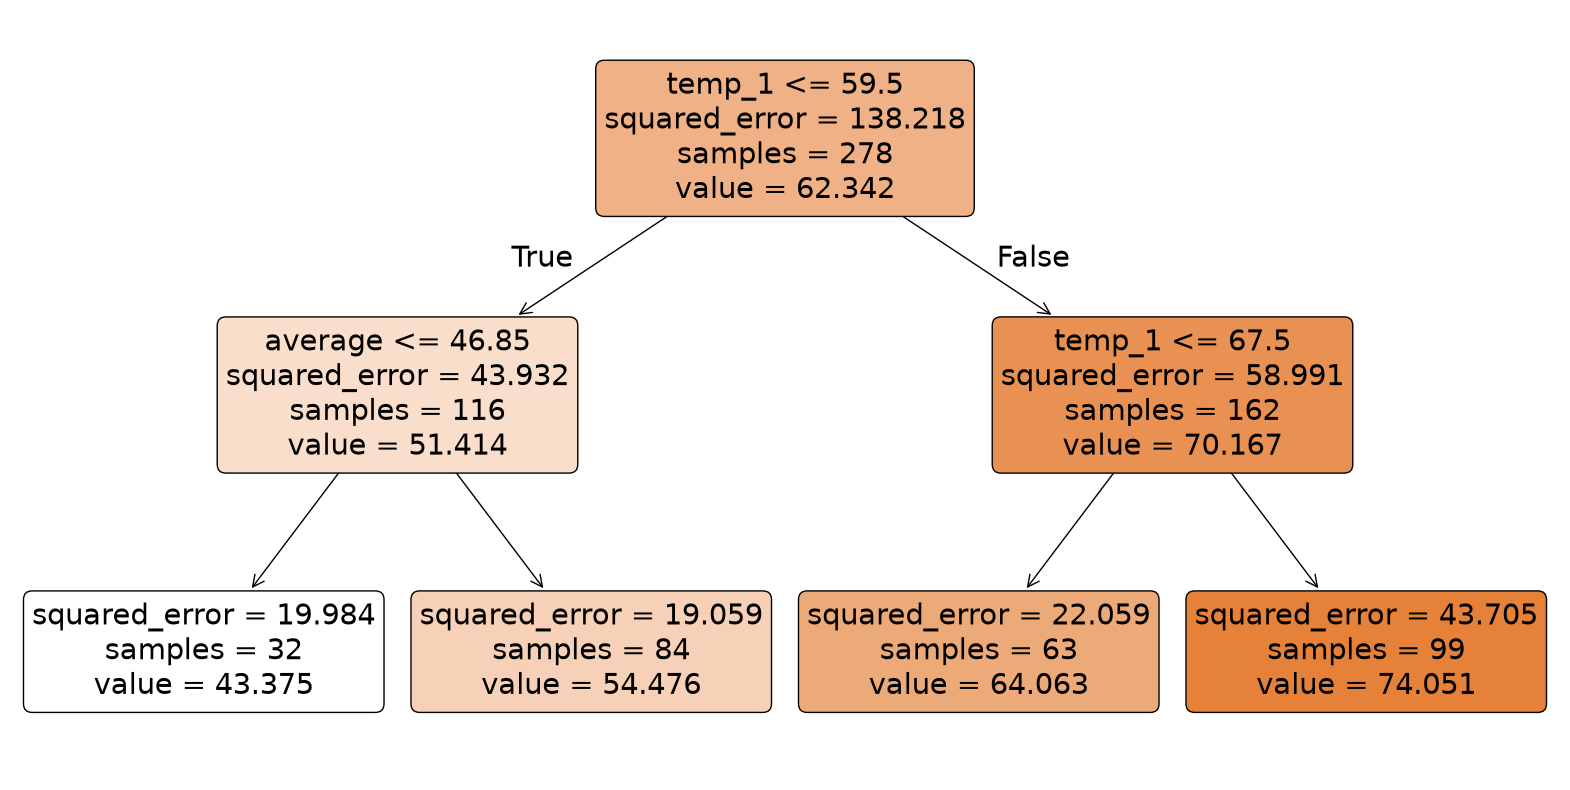

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(modelo, feature_names=X.columns, filled=True, rounded=True, max_depth=3) # max_depth=3 solo para visualizar los primeros niveles
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [15]:
from sklearn.tree import DecisionTreeRegressor

modelo = DecisionTreeRegressor(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

### 8. Vuelve a evaluar tu modelo

In [16]:
y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R2 (Coeficiente de determinación): {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

R2 (Coeficiente de determinación): 0.7787
MAE: 4.2672
MAPE: 0.0674
MSE: 30.9465
RMSE: 5.5630


In [17]:
y_pred_train = modelo.predict(X_train)

print("--- MÉTRICAS TRAIN ---")
print(f"R2 Train: {r2_score(y_train, y_pred_train):.4f}")
print(f"MAE Train: {mean_absolute_error(y_train, y_pred_train):.4f}")

--- MÉTRICAS TRAIN ---
R2 Train: 0.8397
MAE Train: 3.6758


### 9. Vuelve a representar su árbol

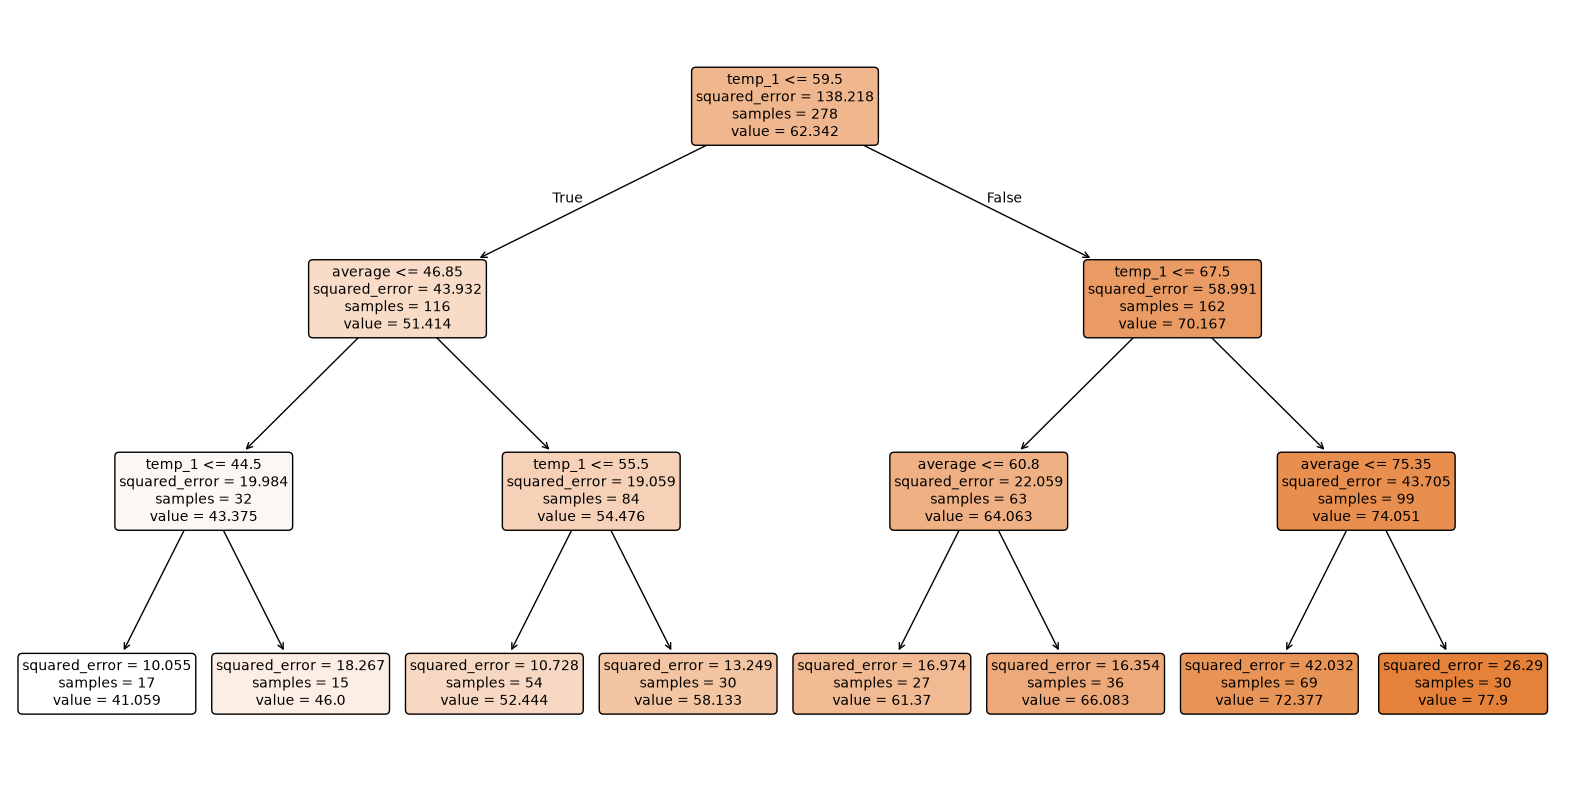

In [18]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(modelo, feature_names=X.columns, filled=True, rounded=True, max_depth=3) # max_depth=3 solo para visualizar los primeros niveles
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [19]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': list(range(2, 15, 2)),  # Empieza en 2: 2, 4, 6, 8, 10, 12, 14
    'min_samples_leaf': list(range(1, 10))       # Este sí puede empezar en 1
}

grid_reg = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',  # También puedes usar 'r2' o 'neg_mean_squared_error'
    n_jobs=-1
)

grid_reg.fit(X_train, y_train)

print("Mejores parámetros:", grid_reg.best_params_)
mejor_modelo_reg = grid_reg.best_estimator_

# Evaluación del mejor modelo
y_pred_best = mejor_modelo_reg.predict(X_test)
print(f"R2 test: {r2_score(y_test, y_pred_best):.4f}")
print(f"MAE test: {mean_absolute_error(y_test, y_pred_best):.4f}")


Mejores parámetros: {'max_depth': 4, 'min_samples_leaf': 6, 'min_samples_split': 14}
R2 test: 0.7938
MAE test: 4.0218


In [20]:
y_pred_train = modelo.predict(X_train)

print("--- MÉTRICAS TRAIN ---")
print(f"R2 Train: {r2_score(y_train, y_pred_train):.4f}")
print(f"MAE Train: {mean_absolute_error(y_train, y_pred_train):.4f}")

--- MÉTRICAS TRAIN ---
R2 Train: 0.8397
MAE Train: 3.6758


### 11. Obten el `feature_importances` de cada variable en el último modelo

  Variable  Importancia
1   temp_1     0.863797
2  average     0.133345
3   friend     0.002859
0   temp_2     0.000000


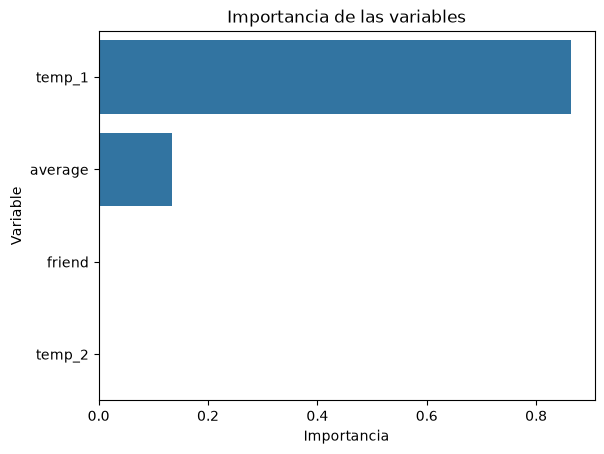

In [21]:
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': mejor_modelo_reg.feature_importances_
}).sort_values(by='Importancia', ascending=False)

print(importancias)

# Opcional: gráfico de barras
sns.barplot(data=importancias, x='Importancia', y='Variable')
plt.title('Importancia de las variables')
plt.show()


### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Crear variable objetivo binaria (1 si > 59°F, 0 si <= 59°F)
y_clf = (df['actual'] > 59).astype(int)

# 2. División train/test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# 3. Grid Search con Cross Validation
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': list(range(2, 15, 2)),  # Empieza en 2: 2, 4, 6, 8, 10, 12, 14
    'min_samples_leaf': list(range(1, 10))       # Este sí puede empezar en 1
}

grid_clf = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_clf.fit(X_train_c, y_train_c)

# 4. Evaluación
print("Mejores parámetros clasificación:", grid_clf.best_params_)
mejor_modelo_clf = grid_clf.best_estimator_
y_pred_c = mejor_modelo_clf.predict(X_test_c)

print(f"Accuracy en test: {accuracy_score(y_test_c, y_pred_c):.4f}\n")
print("Matriz de confusión:\n", confusion_matrix(y_test_c, y_pred_c))
print("\nReporte de clasificación:\n", classification_report(y_test_c, y_pred_c))



Mejores parámetros clasificación: {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
Accuracy en test: 0.9143

Matriz de confusión:
 [[23  6]
 [ 0 41]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0       1.00      0.79      0.88        29
           1       0.87      1.00      0.93        41

    accuracy                           0.91        70
   macro avg       0.94      0.90      0.91        70
weighted avg       0.93      0.91      0.91        70

